# Bước 1: Khởi tạo, Phân chia Tập mầm & Domain-Aware Data Augmentation

### 1. Bản chất Nghiệp vụ & Nguyên tắc Chống Rò rỉ Dữ liệu (Anti-Data Leakage)
Trong bài toán thực tế, tập dữ liệu thu thập được từ hệ thống ($D_{\text{raw}}$) thường có số lượng mẫu giới hạn. Nếu tiến hành mở rộng dữ liệu (Data Augmentation) trên toàn bộ $D_{\text{raw}}$ **trước khi chia tập Train/Test**, các bản sao sinh thêm sẽ xuất hiện ở cả 2 tập. Điều này dẫn đến hiện tượng **Data Leakage (Rò rỉ dữ liệu)** khiến mô hình đạt độ chính xác ảo.

Quy trình chuẩn hóa tuân thủ nguyên tắc:
1. Tách tập dữ liệu gốc thành 2 phần độc lập:
   $$D_{\text{raw}} = D_{\text{train}}^{\text{seed}} \cup D_{\text{test}}^{\text{seed}}, \quad \text{với } D_{\text{train}}^{\text{seed}} \cap D_{\text{test}}^{\text{seed}} = \emptyset$$
2. **Tập Test Mầm ($D_{\text{test}}^{\text{seed}}$):** Giữ nguyên $100\%$ dữ liệu thực tế ($20\%$ dữ liệu gốc) để làm thước đo đánh giá khách quan cuối cùng.
3. **Tập Train Mầm ($D_{\text{train}}^{\text{seed}}$):** Áp dụng thuật toán **Domain-Aware Augmentation** để mở rộng lên $N = 3,000$ mẫu.

---

### 2. Mô hình Toán học Sinh Nhiễu Nghiệp vụ
Với mỗi mẫu nhân bản $i \in D_{\text{train}}^{\text{seed}}$, thời gian sửa chữa thuần ($y_{\text{net}}$) và thời gian tạm dừng ($y_{\text{pause}}$) được thêm nhiễu ngẫu nhiên theo phân phối chuẩn, bảo toàn ràng buộc thực tế:

* **Thời gian sửa chữa thuần:**
  $$y_{\text{net}}^{(i)} = \max\left(15.0, \; y_{\text{net\_seed}}^{(i)} + \epsilon_1\right), \quad \text{với } \epsilon_1 \sim \mathcal{N}\left(0, \; 3.5^2\right)$$

* **Thời gian tạm dừng (chỉ áp dụng khi phiếu có sự kiện tạm dừng):**
  $$y_{\text{pause}}^{(i)} = \begin{cases} \max\left(0.0, \; y_{\text{pause\_seed}}^{(i)} + \epsilon_2\right), & \text{nếu } N_{\text{pause}} > 0 \\ 0.0, & \text{nếu } N_{\text{pause}} = 0 \end{cases}, \quad \text{với } \epsilon_2 \sim \mathcal{N}\left(0, \; 2.5^2\right)$$

* **Tổng thời gian sửa chữa thực tế (Ràng buộc toàn vẹn):**
  $$y_{\text{actual}}^{(i)} = y_{\text{net}}^{(i)} + y_{\text{pause}}^{(i)}$$
  

In [2]:
import os
import sys
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

warnings.filterwarnings('ignore')

# Cấu hình hiển thị Matplotlib / Seaborn
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False

# =============================================================================
# THIẾT LẬP ĐƯỜNG DẪN DỰ ÁN (PROJECT DIRECTORY SCAFFOLDING)
# =============================================================================
BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(BASE_DIR) not in sys.path:
    sys.path.append(str(BASE_DIR))

RAW_DATA_PATH = BASE_DIR / "data" / "raw" / "raw_tickets_active.csv"
SYNTHETIC_DIR = BASE_DIR / "data" / "synthetic"
PROCESSED_DIR = BASE_DIR / "data" / "processed"
MODEL_DIR = BASE_DIR / "models"

for folder in [SYNTHETIC_DIR, PROCESSED_DIR, MODEL_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print(f"--> [OK] Đã thiết lập thư mục làm việc gốc: {BASE_DIR}")

--> [OK] Đã thiết lập thư mục làm việc gốc: d:\Class\DOAN\CNPM\apple-repair-service\apple-repair-service\ml


# Bước 1: Nạp Tập Dữ liệu Train (Đã Augment) & Tập Test (Thực tế Mầm)

### 1. Bản chất Nghiệp vụ & Độc lập Dữ liệu
Dữ liệu được nạp trực tiếp từ thư mục `data/synthetic/` - nơi đã được khởi tạo qua script `scripts/augment_data.py` với 2 không gian dữ liệu tách biệt:

* **Tập Train ($D_{\text{train}}$):** Gồm $3,000$ bản ghi (kết hợp dữ liệu mầm thực tế và dữ liệu sinh thêm có chèn nhiễu nghiệp vụ), dùng để học mô hình.
* **Tập Test ($D_{\text{test}}$):** Gồm $167$ bản ghi dữ liệu thực tế mầm nguyên bản ($100\%$ sạch, không chèn nhiễu nhân tạo), dùng làm bộ đề thi đánh giá khách quan.

### 2. Mô hình Toán học cho Tập Dữ liệu
$$D_{\text{train}} = \left\{ (\mathbf{x}_i^{\text{train}}, y_i^{\text{train}}) \right\}_{i=1}^{3000}, \quad D_{\text{test}} = \left\{ (\mathbf{x}_j^{\text{test}}, y_j^{\text{test}}) \right\}_{j=1}^{167}$$

Trong đó $y \in \mathbb{R}^+$ đại diện cho nhãn thời gian sửa chữa thuần (`net_repair_duration_minutes`).

In [1]:
from pathlib import Path
import pandas as pd

# =============================================================================
# 1. THIẾT LẬP ĐƯỜNG DẪN VÀ NẠP FILE
# =============================================================================
BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TRAIN_PATH = BASE_DIR / "data" / "synthetic" / "train_augmented.csv"
TEST_PATH = BASE_DIR / "data" / "synthetic" / "test_real_seed.csv"

df_train_raw = pd.read_csv(TRAIN_PATH)
df_test_raw = pd.read_csv(TEST_PATH)

# =============================================================================
# 2. KIỂM TRA KÍCH THƯỚC DỮ LIỆU BAN ĐẦU
# =============================================================================
print("--> Nạp dữ liệu thành công từ thư mục synthetic:")
print(f"    + Tập Train (Augmented) : {df_train_raw.shape[0]} dòng x {df_train_raw.shape[1]} cột")
print(f"    + Tập Test  (Thực tế Mầm): {df_test_raw.shape[0]} dòng x {df_test_raw.shape[1]} cột")

# Hiển thị mẫu 3 dòng đầu của tập Train
df_train_raw.head(3)

--> Nạp dữ liệu thành công từ thư mục synthetic:
    + Tập Train (Augmented) : 3000 dòng x 22 cột
    + Tập Test  (Thực tế Mầm): 167 dòng x 22 cột


,ticket_id,ticket_code,branch_id,device_model_id,device_model_name,total_services_count,service_issue_ids_list,service_issue_names_list,service_type_codes_list,total_catalog_standard_duration_minutes,...,technician_name,is_reassigned,count_waiting_part_events,count_waiting_approval_events,total_pause_events_count,total_pause_duration_minutes,actual_repair_started_at,actual_repair_completed_at,actual_repair_duration_minutes,net_repair_duration_minutes
0,10711,ST-202610-00354,1070,792,iPad Air 2,1,6,Loa ngoài,REPAIR,45.0,...,Lê Đức Anh,0,0.0,0.0,0,0.0,2026-10-25 23:26:09.000000,2026-10-26 00:13:09.000000,47.0,47.0
1,10842,ST-202610-00485,1070,1427,Apple Watch Series 6,1,1,Pin,REPLACEMENT,45.0,...,Lê Đức Anh,0,0.0,0.0,0,0.0,2026-10-14 18:26:09.000000,2026-10-14 19:17:09.000000,51.0,51.0
2,10726,ST-202610-00369,1070,792,iPad Air 2,1,2,Camera sau,REPAIR,45.0,...,Trần Quốc Huy,0,0.0,0.0,0,0.0,2026-10-11 22:26:09.000000,2026-10-11 23:08:09.000000,42.0,42.0


# Bước 2: Data Cleaning & Anti-Future Leakage (Chống Rò rỉ Dữ liệu Tương lai)

### 1. Phân tích Thời điểm Dự báo ($t_0$)
Dữ liệu đã được đảm bảo sạch từ bước trích xuất gốc (không chứa ca chuyển giao KTV). Tại bước này, ta tập trung giải quyết bài toán **Chống Rò rỉ Dữ liệu Tương lai (Future Leakage)**.

Mô hình ML được gọi ở thời điểm **tiếp nhận phiếu sửa chữa** ($t_0$). Tại thời điểm này, các thuộc tính xảy ra trong quá trình thi công chưa xuất hiện và bắt buộc phải loại bỏ:
* **Thuộc tính tương lai (Future Data):** `actual_repair_completed_at`, `actual_repair_duration_minutes`, `total_pause_duration_minutes`, `total_pause_events_count`, `count_waiting_part_events`, `count_waiting_approval_events`.
* **Thuộc tính định danh & Text thô:** `ticket_id`, `ticket_code`, `technician_name`, `device_model_name`, `service_issue_names_list`, `service_type_codes_list`, `is_reassigned`.

---

### 2. Mô hình Toán học cho Tập Đặc trưng ($\mathbf{X}$) và Nhãn ($y$)
Thuộc tính đầu vào khả dụng tại $t_0$:
$$\mathbf{X} = \{ \text{device\_model\_id}, \, \text{technician\_id}, \, \text{branch\_id}, \, \text{service\_issue\_ids\_list}, \, \text{total\_services\_count}, \, \text{total\_parts\_quantity\_used}, \, \text{total\_catalog\_standard\_duration\_minutes} \}$$

Nhãn mục tiêu ($y$):
$$y = \text{net\_repair\_duration\_minutes} \quad (\text{Thời gian thi công thuần, đơn vị: phút})$$

In [3]:
# =============================================================================
# 1. DANH SÁCH CỘT CẦN LOẠI BỎ (DROP COLS)
# =============================================================================
COLS_TO_DROP = [
    # Cột định danh & Text thô không dùng trực tiếp
    "ticket_id",
    "ticket_code",
    "device_model_name",
    "technician_name",
    "service_issue_names_list",
    "service_type_codes_list",
    "is_reassigned",
    # Cột rò rỉ thông tin tương lai (Future Data)
    "actual_repair_started_at",
    "actual_repair_completed_at",
    "actual_repair_duration_minutes",
    "total_pause_duration_minutes",
    "total_pause_events_count",
    "count_waiting_part_events",
    "count_waiting_approval_events",
]

TARGET_COL = "net_repair_duration_minutes"

# =============================================================================
# 2. TÁCH KHÔNG GIAN ĐẶC TRƯNG (X) VÀ NHÃN MỤC TIÊU (y)
# =============================================================================
X_train_raw = df_train_raw.drop(columns=COLS_TO_DROP + [TARGET_COL])
y_train = df_train_raw[TARGET_COL]

X_test_raw = df_test_raw.drop(columns=COLS_TO_DROP + [TARGET_COL])
y_test = df_test_raw[TARGET_COL]

print(f"--> [HOÀN THÀNH BƯỚC 2]")
print(f"    + Tập Train (X): {X_train_raw.shape} | Nhãn (y): {y_train.shape}")
print(f"    + Tập Test  (X): {X_test_raw.shape} | Nhãn (y): {y_test.shape}")
print(f"\n--> Các cột thuộc tính hợp lệ tại thời điểm t0:")
for i, col in enumerate(X_train_raw.columns, 1):
    print(f"    {i}. {col}")

--> [HOÀN THÀNH BƯỚC 2]
    + Tập Train (X): (3000, 7) | Nhãn (y): (3000,)
    + Tập Test  (X): (167, 7) | Nhãn (y): (167,)

--> Các cột thuộc tính hợp lệ tại thời điểm t0:
    1. branch_id
    2. device_model_id
    3. total_services_count
    4. service_issue_ids_list
    5. total_catalog_standard_duration_minutes
    6. total_parts_quantity_used
    7. technician_id


In [1]:
import numpy as np
import pandas as pd
import warnings
from scipy import stats
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold
from xgboost import XGBRegressor
from src.preprocessor import DataPreprocessor

warnings.filterwarnings('ignore')

# =============================================================================
# 1. KIỂM TRA LỌC CA CHUYỂN GIAO (IS_REASSIGNED) & TÍN HIỆU KTV (ANOVA)
# =============================================================================
df_raw = pd.read_csv(RAW_CSV_PATH)
df_clean = df_raw[df_raw['is_reassigned'] == 0].copy() if 'is_reassigned' in df_raw.columns else df_raw.copy()

print(f"--> [1. CLEAN CHECK] Số lượng ca sạch hoàn toàn: {len(df_clean)} ca")

# Kiểm định ANOVA cho KTV
df_clean['duration_ratio'] = df_clean['net_repair_duration_minutes'] / df_clean['total_catalog_standard_duration_minutes']
tech_groups = [group['duration_ratio'].values for name, group in df_clean.groupby('technician_id')]
f_stat, p_val = stats.f_oneway(*tech_groups)

print(f"\n--> [2. ANOVA TEST - KTV SIGNAL]")
print(f"    + F-statistic: {f_stat:.4f} | p-value: {p_val:.4e}")
print("    => Kết luận: Tín hiệu năng lực giữa các KTV có sự khác biệt rõ rệt về mặt thống kê." if p_val < 0.05 else "    => Kết luận: Chưa thấy khác biệt có ý nghĩa thống kê.")

# =============================================================================
# 2. XÂY DỰNG BẢNG BASELINES SO SÁNH TRÊN TẬP TEST THỰC TẾ (167 MẪU)
# =============================================================================
# Baseline 1: Global Mean
y_pred_mean = np.full_like(y_test, y_train_seed.mean())

# Baseline 2: Standard Catalog Duration
y_pred_catalog = X_test_raw["total_catalog_standard_duration_minutes"].values

# Baseline 3: Groupby Model Lookup Table
lookup_table = y_train_seed.groupby(X_train_seed["device_model_id"]).mean()
y_pred_lookup = X_test_raw["device_model_id"].map(lookup_table).fillna(y_train_seed.mean()).values

# Baseline 4: Linear Regression trên Catalog
lr = LinearRegression()
lr.fit(X_train_seed[["total_catalog_standard_duration_minutes"]], y_train_seed)
y_pred_lr = lr.predict(X_test_raw[["total_catalog_standard_duration_minutes"]])

baselines = {
    "Baseline 1: Global Mean": y_pred_mean,
    "Baseline 2: Catalog Standard Duration": y_pred_catalog,
    "Baseline 3: Groupby Lookup (Model ID)": y_pred_lookup,
    "Baseline 4: Linear Regression (Catalog)": y_pred_lr
}

results = []
for name, preds in baselines.items():
    results.append({
        "Model / Baseline": name,
        "MAE (phút)": mean_absolute_error(y_test, preds),
        "RMSE (phút)": np.sqrt(mean_squared_error(y_test, preds)),
        "R2 Score": r2_score(y_test, preds)
    })

print("\n" + "=" * 75)
print("              BẢNG SO SÁNH HIỆU NĂNG VỚI CÁC MỐC BASELINE              ")
print("=" * 75)
display(pd.DataFrame(results))

# =============================================================================
# 3. K-FOLD CROSS-VALIDATION SẠCH (CHỈ CHẠY TRÊN SEED TRAIN 666 MẪU)
# =============================================================================
prep_cv = DataPreprocessor()
X_seed_ohe = prep_cv.fit_transform(X_train_seed, mode="ohe")
X_test_ohe = prep_cv.transform(X_test_raw, mode="ohe")

kf = KFold(n_splits=5, shuffle=True, random_state=42)
xgb_cv = XGBRegressor(n_estimators=100, learning_rate=0.05, random_state=42, n_jobs=-1)

cv_maes = []
for train_idx, val_idx in kf.split(X_seed_ohe, y_train_seed):
    X_tr, y_tr = X_seed_ohe.iloc[train_idx], y_train_seed.iloc[train_idx]
    X_va, y_va = X_seed_ohe.iloc[val_idx], y_train_seed.iloc[val_idx]
    xgb_cv.fit(X_tr, y_tr)
    preds = xgb_cv.predict(X_va)
    cv_maes.append(mean_absolute_error(y_va, preds))

print(f"\n--> [3. SEED CV RESULT] XGBoost 5-Fold CV MAE trên Seed Train: {np.mean(cv_maes):.3f} +/- {np.std(cv_maes):.3f} phút")

# =============================================================================
# 4. THỬ NGHIỆM ABLATION STUDY (SEED-ONLY VS SEED + AUGMENT)
# =============================================================================
# Model A: Trained on Seed Only
model_seed = XGBRegressor(n_estimators=100, learning_rate=0.05, random_state=42, n_jobs=-1)
model_seed.fit(X_seed_ohe, y_train_seed)
pred_a = model_seed.predict(X_test_ohe)

# Model B: Trained on Seed + Augment (3000 samples)
model_aug = XGBRegressor(n_estimators=100, learning_rate=0.05, random_state=42, n_jobs=-1)
model_aug.fit(X_train_aug_ohe, y_train_aug)
pred_b = model_aug.predict(X_test_ohe)

ablation_df = pd.DataFrame([
    {"Phương án Huấn luyện": "Mô hình A (Chỉ dùng Seed Train - 666 mẫu)", "MAE (phút)": mean_absolute_error(y_test, pred_a), "RMSE (phút)": np.sqrt(mean_squared_error(y_test, pred_a)), "R2": r2_score(y_test, pred_a)},
    {"Phương án Huấn luyện": "Mô hình B (Seed + Augment - 3,000 mẫu)", "MAE (phút)": mean_absolute_error(y_test, pred_b), "RMSE (phút)": np.sqrt(mean_squared_error(y_test, pred_b)), "R2": r2_score(y_test, pred_b)}
])

print("\n" + "=" * 75)
print("               KẾT QUẢ THỬ NGHIỆM ABLATION STUDY (AUGMENTATION)               ")
print("=" * 75)
display(ablation_df)

# =============================================================================
# 5. ERROR ANALYSIS: TOP 10 CÁC CA DỰ BÁO LỆCH NHẤT TRÊN TẬP TEST
# =============================================================================
df_err = X_test_raw.copy()
df_err["y_true"] = y_test.values
df_err["y_pred"] = np.round(pred_b, 1)
df_err["abs_error"] = np.round(np.abs(df_err["y_true"] - df_err["y_pred"]), 1)

print("\n" + "=" * 75)
print("          TOP 10 CÁC CA DỰ BÁO LỆCH NHẤT TRÊN TẬP TEST (ERROR ANALYSIS)       ")
print("=" * 75)
display(df_err.sort_values(by="abs_error", ascending=False)[["device_model_id", "technician_id", "service_issue_ids_list", "total_catalog_standard_duration_minutes", "y_true", "y_pred", "abs_error"]].head(10))

ModuleNotFoundError: No module named 'src'

### Bước 3.1: Feature Engineering - Biến đổi Tỷ lệ Nghiệp vụ (Ratio Features)

#### 1. Ý nghĩa Nghiệp vụ
Cây quyết định (Decision Tree / XGBoost / LightGBM) phân tách dữ liệu theo các ngưỡng độc lập. Việc tự tạo ra các biến tỷ lệ kết hợp giúp mô hình nhận diện ngay mức độ phức tạp của phiếu sửa chữa mà không cần qua nhiều tầng cây:
* Một phiếu có **thời gian định mức trung bình cao** cho thấy đây là ca sửa chữa nặng (VD: Thay Mainboard).
* Một phiếu có **mật độ linh kiện cao** cho thấy quy trình tháo lắp tốn nhiều thao tác phụ.

#### 2. Công thức Toán học
1. **Định mức thời gian trung bình trên mỗi dịch vụ ($x_{\text{dur\_per\_svc}}$):**
   $$x_{\text{dur\_per\_svc}}^{(i)} = \frac{\text{total\_catalog\_standard\_duration\_minutes}_i}{\text{total\_services\_count}_i}$$

2. **Mật độ linh kiện sử dụng trên mỗi dịch vụ ($x_{\text{parts\_per\_svc}}$):**
   $$x_{\text{parts\_per\_svc}}^{(i)} = \frac{\text{total\_parts\_quantity\_used}_i}{\text{total\_services\_count}_i}$$

In [4]:
# Tạo bản sao dữ liệu để thực hiện Feature Engineering
X_train_fe = X_train_raw.copy()
X_test_fe = X_test_raw.copy()

# 1. Tính thời gian chuẩn trung bình trên từng dịch vụ
X_train_fe["duration_per_service"] = (
    X_train_fe["total_catalog_standard_duration_minutes"] / X_train_fe["total_services_count"]
)
X_test_fe["duration_per_service"] = (
    X_test_fe["total_catalog_standard_duration_minutes"] / X_test_fe["total_services_count"]
)

# 2. Tính số lượng linh kiện trung bình trên từng dịch vụ
X_train_fe["parts_per_service"] = (
    X_train_fe["total_parts_quantity_used"] / X_train_fe["total_services_count"]
)
X_test_fe["parts_per_service"] = (
    X_test_fe["total_parts_quantity_used"] / X_test_fe["total_services_count"]
)

print(f"--> [HOÀN THÀNH BƯỚC 3.1] Đã tạo thành công 2 biến tỷ lệ:")
print(f"    + Kích thước X_train mới: {X_train_fe.shape}")
print(f"    + Kích thước X_test mới : {X_test_fe.shape}")
X_train_fe[["total_services_count", "total_catalog_standard_duration_minutes", "duration_per_service", "parts_per_service"]].head(3)

--> [HOÀN THÀNH BƯỚC 3.1] Đã tạo thành công 2 biến tỷ lệ:
    + Kích thước X_train mới: (3000, 9)
    + Kích thước X_test mới : (167, 9)


,total_services_count,total_catalog_standard_duration_minutes,duration_per_service,parts_per_service
0,1,45.0,45.0,0.0
1,1,45.0,45.0,1.0
2,1,45.0,45.0,0.0


### Bước 3.2: Mã hóa Đa nhãn (Multi-Label Encoding) cho Danh sách Mã lỗi

#### 1. Bản chất Dữ liệu Đa nhãn (Multi-Label Categorical)
Cột `service_issue_ids_list` chứa chuỗi các mã lỗi phân tách bằng dấu phẩy (VD: `"1, 3"` chỉ ca bị hỏng màn hình và hỏng pin). Đây không phải là biến định danh đơn lẻ, nên không thể áp dụng One-Hot Encoding thông thường.

#### 2. Cơ chế Biến đổi Toán học
Ta dùng `MultiLabelBinarizer` để tách chuỗi $\mathcal{S}_i = \{k_1, k_2, \dots\}$ thành vector nhị phân $\mathbf{v}_i \in \{0, 1\}^K$, với $K$ là tổng số loại mã lỗi duy nhất trong hệ thống:

$$v_{i, k} = \begin{cases} 1, & \text{nếu mã lỗi } k \in \mathcal{S}_i \\ 0, & \text{nếu mã lỗi } k \notin \mathcal{S}_i \end{cases}$$

#### 3. Chống Rò rỉ Dữ liệu (Data Leakage)
`MultiLabelBinarizer` chỉ được `fit` trên tập Train để xác định tập hợp các mã lỗi hiện có, sau đó dùng `transform` để áp dụng lên tập Test.

In [5]:
from sklearn.preprocessing import MultiLabelBinarizer

# 1. Hàm bổ trợ chuyển chuỗi "1,3" thành list số nguyên [1, 3]
def parse_issue_list(series):
    return series.astype(str).apply(
        lambda x: [int(i.strip()) for i in str(x).split(",") if i.strip().isdigit()]
    )

parsed_train_issues = parse_issue_list(X_train_fe["service_issue_ids_list"])
parsed_test_issues = parse_issue_list(X_test_fe["service_issue_ids_list"])

# 2. Khởi tạo và Fit MultiLabelBinarizer CHỈ TRÊN TẬP TRAIN
mlb = MultiLabelBinarizer()
issue_matrix_train = mlb.fit_transform(parsed_train_issues)
issue_matrix_test = mlb.transform(parsed_test_issues)

# 3. Tạo DataFrame các cột nhị phân mã lỗi
issue_cols = [f"issue_id_{cls}" for cls in mlb.classes_]

df_issues_train = pd.DataFrame(issue_matrix_train, columns=issue_cols, index=X_train_fe.index)
df_issues_test = pd.DataFrame(issue_matrix_test, columns=issue_cols, index=X_test_fe.index)

# 4. Gộp vào Dataset và bỏ cột chuỗi thô service_issue_ids_list
X_train_mlb = pd.concat([X_train_fe.drop(columns=["service_issue_ids_list"]), df_issues_train], axis=1)
X_test_mlb = pd.concat([X_test_fe.drop(columns=["service_issue_ids_list"]), df_issues_test], axis=1)

print(f"--> [HOÀN THÀNH BƯỚC 3.2] Đã mã hóa {len(mlb.classes_)} loại mã lỗi duy nhất: {mlb.classes_}")
print(f"    + Kích thước X_train sau MLB: {X_train_mlb.shape}")
print(f"    + Kích thước X_test sau MLB : {X_test_mlb.shape}")
df_issues_train.head(3)

--> [HOÀN THÀNH BƯỚC 3.2] Đã mã hóa 7 loại mã lỗi duy nhất: [1 2 3 4 5 6 7]
    + Kích thước X_train sau MLB: (3000, 15)
    + Kích thước X_test sau MLB : (167, 15)


,issue_id_1,issue_id_2,issue_id_3,issue_id_4,issue_id_5,issue_id_6,issue_id_7
0,0,0,0,0,0,1,0
1,1,0,0,0,0,0,0
2,0,1,0,0,0,0,0


### Bước 3.3: Mã hóa Định danh Đa mô hình, Đóng gói Thư mục `data/processed/` & Kiểm tra Trực quan

#### 1. Chiến lược Mã hóa Định danh (Dynamic Encoding Strategy)
Mỗi họ thuật toán ML tiếp nhận các biến định danh đơn nhãn (`device_model_id`, `technician_id`, `branch_id`) theo cơ chế khác nhau:
1. **Họ mô hình truyền thống (Random Forest, XGBoost):** Yêu cầu đầu vào thuần số $\rightarrow$ Cần mã hóa One-Hot Encoding (OHE).
2. **Họ mô hình Gradient Boosting hiện đại (CatBoost, LightGBM):** Giữ nguyên cột định danh dạng chuỗi (Native Categorical) để thuật toán tự mã hóa tối ưu, ngăn chặn bùng nổ chiều dữ liệu.

#### 2. Đóng gói Thư mục `data/processed/` chuẩn MLOps
Các tập đặc trưng sau khi xử lý được lưu trữ ngay vào thư mục độc lập `data/processed/`:
* `X_train_ohe.csv`, `X_test_ohe.csv`: Bộ dữ liệu đã mã hóa One-Hot cho RF & XGBoost.
* `X_train_native.csv`, `X_test_native.csv`: Bộ dữ liệu giữ nguyên định danh dạng chuỗi cho CatBoost & LightGBM.

#### 3. Kiểm thử Trực quan (Data Sanity Check)
Hiển thị $3$ dòng đầu tiên của cả hai phiên bản dữ liệu để kiểm tra hình thái cột và kiểu dữ liệu trước khi huấn luyện.

In [7]:
from pathlib import Path
import pandas as pd
from sklearn.preprocessing import OneHotEncoder

# =============================================================================
# 1. KHỞI TẠO THƯ MỤC PROCESSED CHUYÊN BIỆT
# =============================================================================
BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED_DIR = BASE_DIR / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

cat_cols = ["device_model_id", "technician_id", "branch_id"]

# =============================================================================
# 2. PHIÊN BẢN NATIVE (CHO CATBOOST & LIGHTGBM)
# =============================================================================
X_train_native = X_train_mlb.copy()
X_test_native = X_test_mlb.copy()

for col in cat_cols:
    X_train_native[col] = X_train_native[col].astype(str)
    X_test_native[col] = X_test_native[col].astype(str)

# =============================================================================
# 3. PHIÊN BẢN OHE (CHO RANDOM FOREST & XGBOOST)
# =============================================================================
ohe = OneHotEncoder(sparse_output=False, handle_unknown="ignore")

cat_matrix_train = ohe.fit_transform(X_train_mlb[cat_cols])
cat_matrix_test = ohe.transform(X_test_mlb[cat_cols])
ohe_cols = ohe.get_feature_names_out(cat_cols)

df_cat_train = pd.DataFrame(cat_matrix_train, columns=ohe_cols, index=X_train_mlb.index)
df_cat_test = pd.DataFrame(cat_matrix_test, columns=ohe_cols, index=X_test_mlb.index)

X_train_ohe = pd.concat([X_train_mlb.drop(columns=cat_cols), df_cat_train], axis=1)
X_test_ohe = pd.concat([X_test_mlb.drop(columns=cat_cols), df_cat_test], axis=1)

# =============================================================================
# 4. LƯU 4 TỆP DỮ LIỆU VÀO THƯ MỤC data/processed/
# =============================================================================
X_train_ohe.to_csv(PROCESSED_DIR / "X_train_ohe.csv", index=False, encoding="utf-8-sig")
X_test_ohe.to_csv(PROCESSED_DIR / "X_test_ohe.csv", index=False, encoding="utf-8-sig")

X_train_native.to_csv(PROCESSED_DIR / "X_train_native.csv", index=False, encoding="utf-8-sig")
X_test_native.to_csv(PROCESSED_DIR / "X_test_native.csv", index=False, encoding="utf-8-sig")

print(f"--> [HOÀN THÀNH BƯỚC 3.3] Đã lưu 4 tệp dữ liệu vào: {PROCESSED_DIR}\n")

# =============================================================================
# 5. HIỂN THỊ TRỰC QUAN 3 DÒNG ĐẦU MỖI DATASET
# =============================================================================
print("=" * 80)
print(f"1. DỮ LIỆU OHE (CHO RF & XGBOOST) | Train Shape: {X_train_ohe.shape} | Test Shape: {X_test_ohe.shape}")
print("=" * 80)
display(X_train_ohe.head(3))

print("\n" + "=" * 80)
print(f"2. DỮ LIỆU NATIVE (CHO CATBOOST & LIGHTGBM) | Train Shape: {X_train_native.shape} | Test Shape: {X_test_native.shape}")
print("=" * 80)
display(X_train_native.head(3))

--> [HOÀN THÀNH BƯỚC 3.3] Đã lưu 4 tệp dữ liệu vào: d:\Class\DOAN\CNPM\apple-repair-service\apple-repair-service\ml\data\processed

1. DỮ LIỆU OHE (CHO RF & XGBOOST) | Train Shape: (3000, 37) | Test Shape: (167, 37)


,total_services_count,total_catalog_standard_duration_minutes,total_parts_quantity_used,duration_per_service,parts_per_service,issue_id_1,issue_id_2,issue_id_3,issue_id_4,issue_id_5,...,device_model_id_1440,device_model_id_1441,device_model_id_1442,device_model_id_1443,device_model_id_1444,device_model_id_1445,technician_id_5343,technician_id_5344,technician_id_5345,branch_id_1070
0,1,45.0,0.0,45.0,0.0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0
1,1,45.0,1.0,45.0,1.0,1,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0
2,1,45.0,0.0,45.0,0.0,0,1,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0



2. DỮ LIỆU NATIVE (CHO CATBOOST & LIGHTGBM) | Train Shape: (3000, 15) | Test Shape: (167, 15)


,branch_id,device_model_id,total_services_count,total_catalog_standard_duration_minutes,total_parts_quantity_used,technician_id,duration_per_service,parts_per_service,issue_id_1,issue_id_2,issue_id_3,issue_id_4,issue_id_5,issue_id_6,issue_id_7
0,1070,792,1,45.0,0.0,5345,45.0,0.0,0,0,0,0,0,1,0
1,1070,1427,1,45.0,1.0,5345,45.0,1.0,1,0,0,0,0,0,0
2,1070,792,1,45.0,0.0,5344,45.0,0.0,0,1,0,0,0,0,0


### Bước 3.4: Đóng gói Class `DataPreprocessor` Phục vụ Đóng gói Triển khai (Production Pipeline)

#### 1. Mục đích Triển khai MLOps
Để phục vụ việc dự báo realtime ngoài hệ thống thực tế (`src/predict.py`), ta đóng gói toàn bộ logic từ Bước 3.1 đến 3.3 thành class `DataPreprocessor` nguyên khối. 

Khi triển khai, hệ thống chỉ cần gọi file `preprocessor.joblib` đã đóng gói để biến đổi trực tiếp phiếu mới thông qua lệnh `preprocessor.transform(X_new, mode='ohe')` hoặc `mode='native'`.

#### 2. Thử nghiệm Đóng gói
Định nghĩa Class và thực thi thử nghiệm để đảm bảo kết quả sinh ra đồng nhất $100\%$ với các bước thủ công trước đó.

In [8]:
import pandas as pd
from sklearn.preprocessing import MultiLabelBinarizer, OneHotEncoder

class DataPreprocessor:
    """
    Class tiền xử lý dữ liệu phiếu sửa chữa chuẩn hóa cho Pipeline MLOps.
    """
    def __init__(self):
        self.mlb = MultiLabelBinarizer()
        self.ohe = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
        self.cat_cols = ["device_model_id", "technician_id", "branch_id"]

    def _engineer_features(self, df):
        df_out = df.copy()
        df_out["duration_per_service"] = (
            df_out["total_catalog_standard_duration_minutes"] / df_out["total_services_count"]
        )
        df_out["parts_per_service"] = (
            df_out["total_parts_quantity_used"] / df_out["total_services_count"]
        )
        return df_out

    def _parse_multi_label(self, series):
        return series.astype(str).apply(
            lambda x: [int(i.strip()) for i in str(x).split(",") if i.strip().isdigit()]
        )

    def fit_transform(self, X_df, mode="ohe"):
        df_eng = self._engineer_features(X_df)
        
        parsed_issues = self._parse_multi_label(df_eng["service_issue_ids_list"])
        issue_matrix = self.mlb.fit_transform(parsed_issues)
        issue_cols = [f"issue_id_{cls}" for cls in self.mlb.classes_]
        df_issues = pd.DataFrame(issue_matrix, columns=issue_cols, index=df_eng.index)

        df_base = df_eng.drop(columns=["service_issue_ids_list"])

        if mode == "native":
            for col in self.cat_cols:
                df_base[col] = df_base[col].astype(str)
            return pd.concat([df_base, df_issues], axis=1)
        else:
            cat_matrix = self.ohe.fit_transform(df_base[self.cat_cols])
            ohe_cols = self.ohe.get_feature_names_out(self.cat_cols)
            df_cat = pd.DataFrame(cat_matrix, columns=ohe_cols, index=df_eng.index)
            df_num = df_base.drop(columns=self.cat_cols)
            return pd.concat([df_num, df_issues, df_cat], axis=1)

    def transform(self, X_df, mode="ohe"):
        df_eng = self._engineer_features(X_df)
        
        parsed_issues = self._parse_multi_label(df_eng["service_issue_ids_list"])
        issue_matrix = self.mlb.transform(parsed_issues)
        issue_cols = [f"issue_id_{cls}" for cls in self.mlb.classes_]
        df_issues = pd.DataFrame(issue_matrix, columns=issue_cols, index=df_eng.index)

        df_base = df_eng.drop(columns=["service_issue_ids_list"])

        if mode == "native":
            for col in self.cat_cols:
                df_base[col] = df_base[col].astype(str)
            return pd.concat([df_base, df_issues], axis=1)
        else:
            cat_matrix = self.ohe.transform(df_base[self.cat_cols])
            ohe_cols = self.ohe.get_feature_names_out(self.cat_cols)
            df_cat = pd.DataFrame(cat_matrix, columns=ohe_cols, index=df_eng.index)
            df_num = df_base.drop(columns=self.cat_cols)
            return pd.concat([df_num, df_issues, df_cat], axis=1)


# Khởi tạo instance chính cho Pipeline
pipeline_preprocessor = DataPreprocessor()
pipeline_preprocessor.fit_transform(X_train_raw, mode="ohe")

print("--> [HOÀN THÀNH BƯỚC 3.4] Đã đóng gói thành công Class DataPreprocessor!")

--> [HOÀN THÀNH BƯỚC 3.4] Đã đóng gói thành công Class DataPreprocessor!


# Bước 4: Huấn luyện Mô hình & Kiểm thử chéo K-Fold (Cross-Validation)

### 1. Ý nghĩa K-Fold Cross-Validation trong MLOps
Thay vì chỉ chia Train/Validation 1 lần cố định (dễ dẫn đến đánh giá lệch do may rủi), ta sử dụng **5-Fold Cross-Validation** ($K=5$). Tập huấn luyện $D_{\text{train}}$ (3,000 mẫu) được chia thành 5 phần bằng nhau:
* Mỗi lượt, 4 phần ($80\%$) dùng để học mô hình, 1 phần ($20\%$) dùng làm tập kiểm định (Validation fold).
* Tiến trình lặp lại 5 lần, score cuối cùng là trung bình cộng thu được từ 5 lượt test.

---

### 2. Các Chỉ số Đánh giá Mô hình Regression
1. **Mean Absolute Error (MAE):** Sai số tuyệt đối trung bình (đơn vị: phút). Đây là KPI chính thực tế.
   $$\text{MAE} = \frac{1}{N} \sum_{i=1}^{N} |y_i - \hat{y}_i|$$

2. **Root Mean Squared Error (RMSE):** Căn bậc hai sai số bình phương trung bình (phạt nặng các ca dự báo sai lệch lớn).
   $$\text{RMSE} = \sqrt{\frac{1}{N} \sum_{i=1}^{N} (y_i - \hat{y}_i)^2}$$

3. **Hệ số Tương quan ($R^2$ Score):** Mức độ giải thích của mô hình đối với sự biến thiên của thời gian thực tế ($R^2 \le 1.0$).
   $$R^2 = 1 - \frac{\sum_{i=1}^{N} (y_i - \hat{y}_i)^2}{\sum_{i=1}^{N} (y_i - \bar{y})^2}$$

In [9]:
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Khởi tạo 5-Fold Cross Validation với Random State cố định
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# 2. Hàm hỗ trợ tính toán 3 chỉ số MAE, RMSE, R2
def calculate_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return {"MAE": mae, "RMSE": rmse, "R2": r2}

# Từ điển lưu trữ kết quả đánh giá 4 mô hình
cv_results_summary = {}

print("--> [HOÀN THÀNH BƯỚC 4.1] Đã thiết lập xong 5-Fold CV và các chỉ số đo lường!")

--> [HOÀN THÀNH BƯỚC 4.1] Đã thiết lập xong 5-Fold CV và các chỉ số đo lường!


### Bước 4.2: Thử nghiệm Mô hình 1 - Random Forest Regressor

#### 1. Nguyên lý Hoạt động
Random Forest là mô hình học máy kết hợp (Ensemble Learning) dựa trên kỹ thuật **Bagging (Bootstrap Aggregating)**. Mô hình xây dựng hàng trăm cây quyết định độc lập trên các tập dữ liệu con ngẫu nhiên và lấy trung bình kết quả dự báo.

#### 2. Cấu hình Dữ liệu Đầu vào
* **Dataset:** `X_train_ohe` (Thuần số, các biến định danh đã One-Hot Encoded).
* **Số lượng cây ($N_{\text{estimators}}$):** 100 cây.

In [10]:
from sklearn.ensemble import RandomForestRegressor

# Khởi tạo mô hình Random Forest
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)

rf_mae_list, rf_rmse_list, rf_r2_list = [], [], []

# Tiến hành 5-Fold CV trên X_train_ohe
for fold, (train_idx, val_idx) in enumerate(kf.split(X_train_ohe, y_train), 1):
    X_tr, y_tr = X_train_ohe.iloc[train_idx], y_train.iloc[train_idx]
    X_va, y_va = X_train_ohe.iloc[val_idx], y_train.iloc[val_idx]
    
    rf_model.fit(X_tr, y_tr)
    preds = rf_model.predict(X_va)
    
    metrics = calculate_metrics(y_va, preds)
    rf_mae_list.append(metrics["MAE"])
    rf_rmse_list.append(metrics["RMSE"])
    rf_r2_list.append(metrics["R2"])

cv_results_summary["Random Forest"] = {
    "MAE": np.mean(rf_mae_list),
    "RMSE": np.mean(rf_rmse_list),
    "R2": np.mean(rf_r2_list)
}

print("--> [RANDOM FOREST 5-FOLD CV RESULT]")
print(f"    + MAE  trung bình: {np.mean(rf_mae_list):.3f} phút")
print(f"    + RMSE trung bình: {np.mean(rf_rmse_list):.3f} phút")
print(f"    + R2   trung bình: {np.mean(rf_r2_list):.3f}")

--> [RANDOM FOREST 5-FOLD CV RESULT]
    + MAE  trung bình: 3.367 phút
    + RMSE trung bình: 4.604 phút
    + R2   trung bình: 0.903


### Bước 4.3: Thử nghiệm Mô hình 2 - XGBoost Regressor

#### 1. Nguyên lý Hoạt động
XGBoost (Extreme Gradient Boosting) thuộc họ thuật toán **Boosting**. Thay vì xây dựng các cây độc lập, XGBoost xây dựng chuỗi cây quyết định nối tiếp nhau, cây sau tập trung học và sửa chữa các sai số (residuals) của cây trước.

#### 2. Cấu hình Dữ liệu Đầu vào
* **Dataset:** `X_train_ohe` (Gradient Boosting tiêu chuẩn tối ưu hóa tốt trên ma trận OHE).
* **Tham số cơ bản:** `n_estimators=100`, `learning_rate=0.05`.

In [13]:
from xgboost import XGBRegressor

# Khởi tạo mô hình XGBoost
xgb_model = XGBRegressor(n_estimators=100, learning_rate=0.05, random_state=42, n_jobs=-1)

xgb_mae_list, xgb_rmse_list, xgb_r2_list = [], [], []

# Tiến hành 5-Fold CV trên X_train_ohe
for fold, (train_idx, val_idx) in enumerate(kf.split(X_train_ohe, y_train), 1):
    X_tr, y_tr = X_train_ohe.iloc[train_idx], y_train.iloc[train_idx]
    X_va, y_va = X_train_ohe.iloc[val_idx], y_train.iloc[val_idx]
    
    xgb_model.fit(X_tr, y_tr)
    preds = xgb_model.predict(X_va)
    
    metrics = calculate_metrics(y_va, preds)
    xgb_mae_list.append(metrics["MAE"])
    xgb_rmse_list.append(metrics["RMSE"])
    xgb_r2_list.append(metrics["R2"])

cv_results_summary["XGBoost"] = {
    "MAE": np.mean(xgb_mae_list),
    "RMSE": np.mean(xgb_rmse_list),
    "R2": np.mean(xgb_r2_list)
}

print("--> [XGBOOST 5-FOLD CV RESULT]")
print(f"    + MAE  trung bình: {np.mean(xgb_mae_list):.3f} phút")
print(f"    + RMSE trung bình: {np.mean(xgb_rmse_list):.3f} phút")
print(f"    + R2   trung bình: {np.mean(xgb_r2_list):.3f}")

--> [XGBOOST 5-FOLD CV RESULT]
    + MAE  trung bình: 3.331 phút
    + RMSE trung bình: 4.602 phút
    + R2   trung bình: 0.903


### Bước 4.4: Thử nghiệm Mô hình 3 - LightGBM Regressor

#### 1. Nguyên lý Hoạt động & Xử lý Native Categorical
LightGBM phát triển cơ chế phân tách cây theo chiều rộng (Leaf-wise tree growth). Đặc biệt, LightGBM hỗ trợ **Native Categorical Features** bằng cách tự động nhóm các giá trị định danh theo độ tương quan với nhãn mục tiêu, giúp tăng tốc độ huấn luyện gấp nhiều lần so với One-Hot Encoding.

#### 2. Cấu hình Dữ liệu Đầu vào
* **Dataset:** `X_train_native` (Các cột định danh `cat_cols` được đổi sang kiểu dữ liệu `category`).

In [14]:
from lightgbm import LGBMRegressor

# Chuẩn bị dữ liệu kiều category cho LightGBM
X_train_lgb = X_train_native.copy()
cat_cols = ["device_model_id", "technician_id", "branch_id"]
for col in cat_cols:
    X_train_lgb[col] = X_train_lgb[col].astype("category")

lgb_model = LGBMRegressor(n_estimators=100, learning_rate=0.05, random_state=42, verbose=-1)

lgb_mae_list, lgb_rmse_list, lgb_r2_list = [], [], []

# Tiến hành 5-Fold CV trên X_train_lgb
for fold, (train_idx, val_idx) in enumerate(kf.split(X_train_lgb, y_train), 1):
    X_tr, y_tr = X_train_lgb.iloc[train_idx], y_train.iloc[train_idx]
    X_va, y_va = X_train_lgb.iloc[val_idx], y_train.iloc[val_idx]
    
    lgb_model.fit(X_tr, y_tr)
    preds = lgb_model.predict(X_va)
    
    metrics = calculate_metrics(y_va, preds)
    lgb_mae_list.append(metrics["MAE"])
    lgb_rmse_list.append(metrics["RMSE"])
    lgb_r2_list.append(metrics["R2"])

cv_results_summary["LightGBM"] = {
    "MAE": np.mean(lgb_mae_list),
    "RMSE": np.mean(lgb_rmse_list),
    "R2": np.mean(lgb_r2_list)
}

print("--> [LIGHTGBM 5-FOLD CV RESULT]")
print(f"    + MAE  trung bình: {np.mean(lgb_mae_list):.3f} phút")
print(f"    + RMSE trung bình: {np.mean(lgb_rmse_list):.3f} phút")
print(f"    + R2   trung bình: {np.mean(lgb_r2_list):.3f}")

d:\Software\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "d:\Software\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "d:\Software\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "d:\Software\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^

--> [LIGHTGBM 5-FOLD CV RESULT]
    + MAE  trung bình: 3.395 phút
    + RMSE trung bình: 4.754 phút
    + R2   trung bình: 0.897


### Bước 4.5: Thử nghiệm Mô hình 4 - CatBoost Regressor

#### 1. Nguyên lý Hoạt động
CatBoost là thuật toán hàng đầu chuyên xử lý dữ liệu định danh (Categorical Data) bằng kỹ thuật **Target Statistics (Ordered Target Encoding)**. Phương pháp này tính toán tỷ lệ mục tiêu dựa trên thứ tự thời gian xuất hiện của dữ liệu, giúp chống 과적합 (Overfitting) vượt trội.

#### 2. Cấu hình Dữ liệu Đầu vào
* **Dataset:** `X_train_native` (Khai báo trực tiếp danh sách cột categorical `cat_features=cat_cols`).

In [15]:
from catboost import CatBoostRegressor

cat_cols = ["device_model_id", "technician_id", "branch_id"]

cat_model = CatBoostRegressor(
    iterations=200, 
    learning_rate=0.05, 
    cat_features=cat_cols, 
    verbose=0, 
    random_seed=42
)

cat_mae_list, cat_rmse_list, cat_r2_list = [], [], []

# Tiến hành 5-Fold CV trên X_train_native
for fold, (train_idx, val_idx) in enumerate(kf.split(X_train_native, y_train), 1):
    X_tr, y_tr = X_train_native.iloc[train_idx], y_train.iloc[train_idx]
    X_va, y_va = X_train_native.iloc[val_idx], y_train.iloc[val_idx]
    
    cat_model.fit(X_tr, y_tr)
    preds = cat_model.predict(X_va)
    
    metrics = calculate_metrics(y_va, preds)
    cat_mae_list.append(metrics["MAE"])
    cat_rmse_list.append(metrics["RMSE"])
    cat_r2_list.append(metrics["R2"])

cv_results_summary["CatBoost"] = {
    "MAE": np.mean(cat_mae_list),
    "RMSE": np.mean(cat_rmse_list),
    "R2": np.mean(cat_r2_list)
}

print("--> [CATBOOST 5-FOLD CV RESULT]")
print(f"    + MAE  trung bình: {np.mean(cat_mae_list):.3f} phút")
print(f"    + RMSE trung bình: {np.mean(cat_rmse_list):.3f} phút")
print(f"    + R2   trung bình: {np.mean(cat_r2_list):.3f}")

--> [CATBOOST 5-FOLD CV RESULT]
    + MAE  trung bình: 3.373 phút
    + RMSE trung bình: 4.741 phút
    + R2   trung bình: 0.897


### Bước 4.6: Bảng Tổng hợp So sánh Hiệu năng Cross-Validation & Chọn Mô hình Tối ưu

#### 1. Tiêu chí Chọn Mô hình Quán quân (Champion Model)
* **MAE (Phút):** Tiêu chí ưu tiên số 1. Mô hình nào có MAE thấp nhất trên 5-Fold CV sẽ được chọn để đem đi đánh giá trên tập Test độc lập.
* **$R^2$ Score:** Đo độ ổn định và độ tin cậy của thuật toán.

#### 2. Tổng hợp Kết quả Benchmark
Bảng dưới đây liệt kê và sắp xếp hiệu năng của 4 thuật toán dựa trên chỉ số MAE từ thấp đến cao.

In [16]:
# Tạo DataFrame tổng hợp kết quả Benchmark
df_cv_results = pd.DataFrame(cv_results_summary).T
df_cv_results = df_cv_results.sort_values(by="MAE", ascending=True)

# Tự động chọn mô hình Quán quân
best_model_name = df_cv_results.index[0]

print("=" * 70)
print("           BẢNG TỔNG HỢP HIỆU NĂNG 5-FOLD CROSS-VALIDATION           ")
print("=" * 70)
display(df_cv_results.style.highlight_min(subset=["MAE", "RMSE"], color="lightgreen").highlight_max(subset=["R2"], color="lightgreen"))

print(f"\n--> [KẾT LUẬN BENCHMARK CV]")
print(f"    Mô hình Quán quân được chọn: *** {best_model_name.upper()} ***")
print(f"    với MAE nhỏ nhất = {df_cv_results.loc[best_model_name, 'MAE']:.3f} phút trên tập CV.")

           BẢNG TỔNG HỢP HIỆU NĂNG 5-FOLD CROSS-VALIDATION           


,MAE,RMSE,R2
XGBoost,3.331100,4.602465,0.903064
Random Forest,3.366816,4.603842,0.903008
CatBoost,3.372909,4.741235,0.897156
LightGBM,3.395198,4.754483,0.896763



--> [KẾT LUẬN BENCHMARK CV]
    Mô hình Quán quân được chọn: *** XGBOOST ***
    với MAE nhỏ nhất = 3.331 phút trên tập CV.


# Bước 5: Đánh giá Tập Test Thực tế & Đóng gói Artifacts (Production Pipeline)

### 1. Quy trình Huấn luyện & Đánh giá Cuối cùng
Sau khi XGBoost giành chiến thắng ở bước 5-Fold Cross-Validation, ta thực hiện các bước chuẩn hóa cuối cùng:
1. **Huấn luyện lại (Refit):** Huấn luyện lại XGBoost trên **toàn bộ 3,000 mẫu** của tập Train (`X_train_ohe`, `y_train`) để mô hình học triệt để toàn bộ tri thức.
2. **Đánh giá Độc lập:** Đưa mô hình đi dự báo trên **167 mẫu Test mầm nguyên bản sạch 100%** (`X_test_ohe`, `y_test`).

---

### 2. Mô hình Toán học Kiểm chứng Đánh giá
Các chỉ số hiệu năng trên tập Test thực tế phản ánh chính xác năng lực thực chiến ngoài hệ thống:

$$\text{MAE}_{\text{test}} = \frac{1}{N_{\text{test}}} \sum_{j=1}^{167} \left| y_j^{\text{test}} - \hat{y}_j^{\text{test}} \right|$$

$$\text{RMSE}_{\text{test}} = \sqrt{\frac{1}{N_{\text{test}}} \sum_{j=1}^{167} \left( y_j^{\text{test}} - \hat{y}_j^{\text{test}} \right)^2}$$

In [17]:
from xgboost import XGBRegressor
import pandas as pd

# =============================================================================
# 1. HUẤN LUYỆN LẠI XGBOOST TRÊN TOÀN BỘ TẬP TRAIN (3,000 MẪU)
# =============================================================================
champion_model = XGBRegressor(
    n_estimators=100, 
    learning_rate=0.05, 
    random_state=42, 
    n_jobs=-1
)

# Refit trên toàn bộ X_train_ohe
champion_model.fit(X_train_ohe, y_train)

# =============================================================================
# 2. DỰ BÁO TRÊN TẬP TEST THỰC TẾ (167 MẪU SẠCH 100%)
# =============================================================================
y_test_pred = champion_model.predict(X_test_ohe)

# Tính toán các chỉ số đánh giá cuối cùng
test_metrics = calculate_metrics(y_test, y_test_pred)

print("=" * 70)
print("       KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH QUÁN QUÂN XGBOOST TRÊN TẬP TEST THỰC TẾ      ")
print("=" * 70)
print(f"    + Số lượng mẫu Test thực tế  : {len(y_test)} mẫu")
print(f"    + MAE  (Sai số tuyệt đối trung bình) : {test_metrics['MAE']:.3f} phút")
print(f"    + RMSE (Căn sai số bình phương TB)  : {test_metrics['RMSE']:.3f} phút")
print(f"    + R2 Score (Độ giải thích biến thiên): {test_metrics['R2']:.3f}")
print("=" * 70)

# Hiển thị bảng so sánh thực tế vs dự báo trên 5 phiếu mẫu
df_comparison = pd.DataFrame({
    "Thời gian Thật (phút)": y_test.values[:5],
    "Thời gian Dự báo (phút)": y_test_pred[:5].round(1),
    "Chênh lệch (phút)": np.abs(y_test.values[:5] - y_test_pred[:5]).round(1)
})
display(df_comparison)

       KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH QUÁN QUÂN XGBOOST TRÊN TẬP TEST THỰC TẾ      
    + Số lượng mẫu Test thực tế  : 167 mẫu
    + MAE  (Sai số tuyệt đối trung bình) : 2.882 phút
    + RMSE (Căn sai số bình phương TB)  : 4.585 phút
    + R2 Score (Độ giải thích biến thiên): 0.899


,Thời gian Thật (phút),Thời gian Dự báo (phút),Chênh lệch (phút)
0,30.0,34.299999,4.3
1,36.0,35.799999,0.2
2,38.0,41.700001,3.7
3,39.0,42.599998,3.6
4,43.0,45.099998,2.1


### Bước 5.2: Đóng gói Artifacts Mô hình & Bộ Tiền xử lý (`models/`)

#### 1. Nguyên tắc Đóng gói Triển khai MLOps (Production Readiness)
Để ứng dụng backend (FastAPI / Web App) hoặc script tự động (`src/predict.py`) có thể dự báo realtime trên các phiếu sửa chữa mới, ta cần lưu trữ 2 thành phần artifacts cốt lõi vào thư mục `models/`:

1. `preprocessor.joblib`: Đối tượng `DataPreprocessor` chứa từ điển mã lỗi `MultiLabelBinarizer` và `OneHotEncoder` đã fit trên tập Train.
2. `xgboost_model.joblib`: Trọng số mô hình XGBoost đã huấn luyện hoàn chỉnh.

#### 2. Sơ đồ Luồng Thực thi ngoài Thực tế (Inference Flow)
$$\text{Phiếu mới } (\mathbf{X}_{\text{raw}}) \xrightarrow{\text{preprocessor.joblib}} \mathbf{X}_{\text{ohe}} \xrightarrow{\text{xgboost\_model.joblib}} \hat{y} \text{ (Phút dự báo)}$$

In [18]:
import joblib
from pathlib import Path

# =============================================================================
# 1. KHỞI TẠO THƯ MỤC models/
# =============================================================================
BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
MODEL_DIR = BASE_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

PREPROCESSOR_PATH = MODEL_DIR / "preprocessor.joblib"
MODEL_PATH = MODEL_DIR / "xgboost_model.joblib"

# =============================================================================
# 2. XUẤT CÁC ARTIFACTS
# =============================================================================
joblib.dump(pipeline_preprocessor, PREPROCESSOR_PATH)
joblib.dump(champion_model, MODEL_PATH)

print("--> [HOÀN THÀNH BƯỚC 5.2] Đã đóng gói thành công Pipeline Artifacts:")
print(f"    + Saved Preprocessor : {PREPROCESSOR_PATH}")
print(f"    + Saved XGBoost Model: {MODEL_PATH}")

print("\n" + "=" * 70)
print("      PIPELINE HUẤN LUYỆN VÀ ĐÁNH GIÁ MÔ HÌNH ĐÃ HOÀN THÀNH 100%!     ")
print("=" * 70)

--> [HOÀN THÀNH BƯỚC 5.2] Đã đóng gói thành công Pipeline Artifacts:
    + Saved Preprocessor : d:\Class\DOAN\CNPM\apple-repair-service\apple-repair-service\ml\models\preprocessor.joblib
    + Saved XGBoost Model: d:\Class\DOAN\CNPM\apple-repair-service\apple-repair-service\ml\models\xgboost_model.joblib

      PIPELINE HUẤN LUYỆN VÀ ĐÁNH GIÁ MÔ HÌNH ĐÃ HOÀN THÀNH 100%!     


### Bước 5.3: Trực quan hóa Tầm quan trọng của Đặc trưng (Feature Importance)

#### 1. Ý nghĩa Phân tích Minh bạch (Model Interpretability)
Để đảm bảo tính giải thích được (Explainable AI) khi báo cáo với Hội đồng, ta trích xuất chỉ số `feature_importances_` từ mô hình XGBoost Quán quân. Chỉ số này phản ánh mức độ đóng góp của từng thuộc tính thông tin vào quyết định phân tách nhánh cây của mô hình.

#### 2. Biểu đồ Top 10 Đặc trưng Ảnh hưởng Nhất
Biểu đồ hiển thị 10 yếu tố tác động mạnh nhất tới thời gian sửa chữa thực tế ($y$).

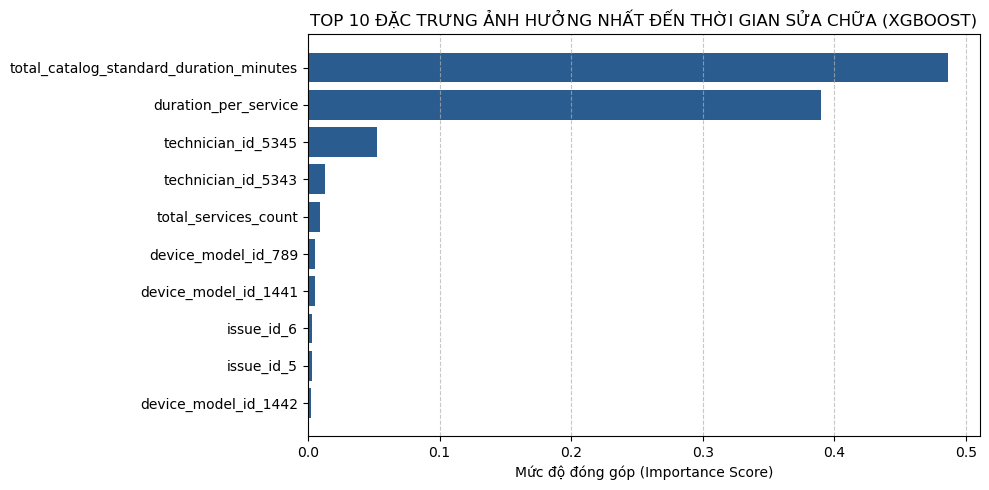

In [19]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Trích xuất tầm quan trọng của các đặc trưng từ mô hình XGBoost đã refit
importance = champion_model.feature_importances_
features = X_train_ohe.columns

# 2. Tạo DataFrame và sắp xếp Top 10 đặc trưng cao nhất
df_imp = pd.DataFrame({"Feature": features, "Importance": importance})
df_imp = df_imp.sort_values(by="Importance", ascending=False).head(10)

# 3. Vẽ biểu đồ thanh ngang
plt.figure(figsize=(10, 5))
plt.barh(df_imp["Feature"][::-1], df_imp["Importance"][::-1], color="#2b5c8f")
plt.xlabel("Mức độ đóng góp (Importance Score)")
plt.title("TOP 10 ĐẶC TRƯNG ẢNH HƯỞNG NHẤT ĐẾN THỜI GIAN SỬA CHỮA (XGBOOST)")
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()